In [6]:
#Libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats 
from scipy.optimize import curve_fit
from pathlib import Path

La funzione è finita? : True
La funzione è definita positiva? : True
La funzione è  simmetrica? : True
La funzione è compatibile, in x = 0, a B+I0? : True


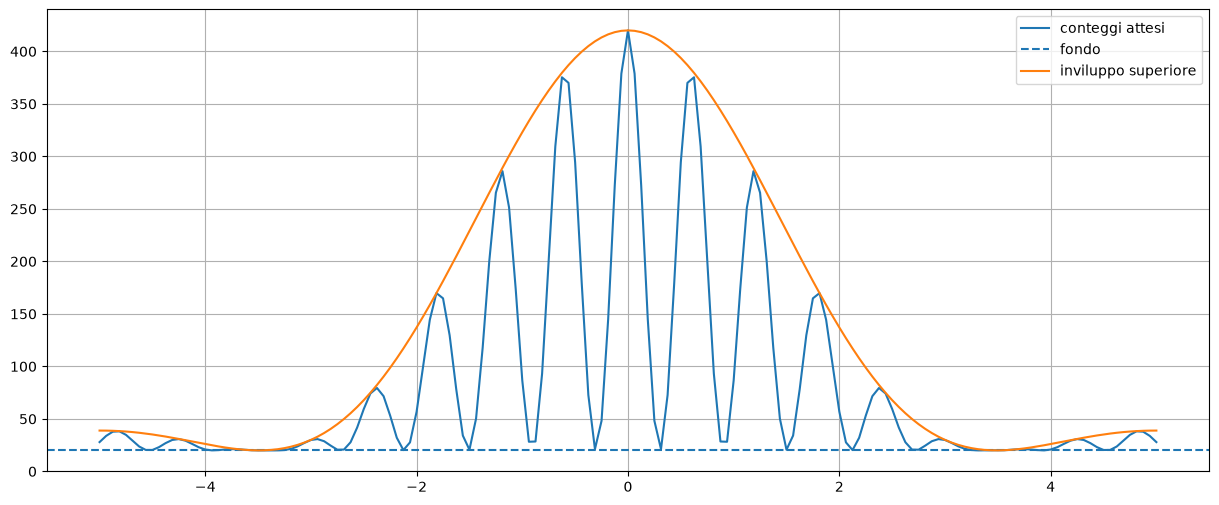

In [14]:
#Attività 1

x_vals = np.linspace(-5,5,161) #Dominio funzione 

def E(x,alpha):
    risultato = np.sinc(alpha*x/np.pi)**2
    return risultato

def C(x, delta):
    risultato =np.cos(delta*x)**2
    return risultato


def media_attesa(B, I0 ,alpha, delta, x):

    mu = B + I0*E(x, alpha)*C(x, delta)
    return mu

B = 20
I0 = 400
alpha = 0.9
delta = 5.20


y = media_attesa( B, I0, alpha, delta, x_vals)

print("La funzione è finita? :",np.all(np.isfinite( y ))) #comando per verificare se la funzione è finita

print("La funzione è definita positiva? :", np.all( y > 0 )) #comando per verificare se la funzione è positiva

print("La funzione è  simmetrica? :",np.allclose( y , y[::-1]) ) #comando oper verificare se la funzione è simmetrica

print("La funzione è compatibile, in x = 0, a B+I0? :",media_attesa( B, I0 , alpha , delta , 0 ) == B + I0
 )
plt.figure(figsize=(15,6))
plt.plot(x_vals,y,label="conteggi attesi")#plot

plt.axhline(B, label="fondo",ls="--")

plt.plot(x_vals,B+I0*E(x_vals,alpha), label="inviluppo superiore")
plt.grid(True)
plt.legend()
plt.show()

La discrepanza è compatibile con una fluttuazione statistica? : True


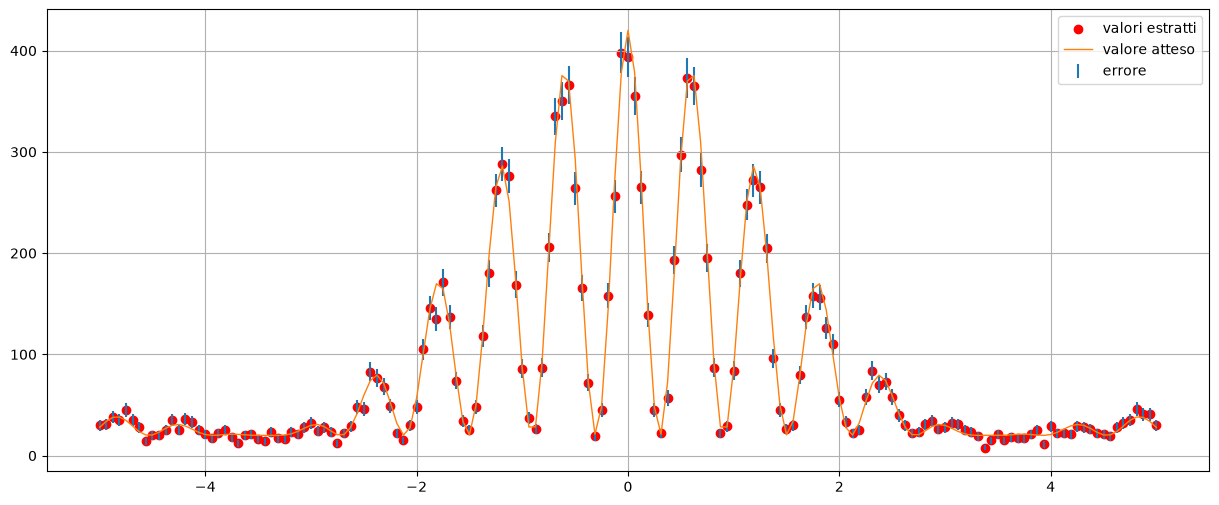

In [36]:
#Attività 2

rng = np.random.default_rng(15647631)  #Seed


mu_list=[] # creo una lista all'interno della quale aggiungo un numero casuale estratto da una poissoniana che ha come media il valore i-esimo di y

for i in y:

    mu_in =rng.poisson(i)

    mu_list.append(mu_in)

mu_vals=np.array(mu_list) # trasformo la list in array

x_centrali_list=[]

for i in x_vals:
    if -1.2 <= i <= 1.2:
        x_centrali_list.append(i)
x_centrali=np.array(x_centrali_list)

y_centrali= media_attesa(B,I0,alpha,delta,x_centrali)#valori teorici di conteggio

sum_yc=np.sum(y_centrali)

mu_centrali= np.array(rng.poisson(y_centrali))

sum_muc= np.sum(mu_centrali)
errors=np.where(mu_vals<1,1,np.sqrt(mu_vals))

z= np.sqrt((sum_yc - sum_muc)**2/sum_yc)
print("La discrepanza è compatibile con una fluttuazione statistica? :", z <= 1 )

plt.figure(figsize=(15,6)) #creo l'immagine e plot

plt.scatter (x_vals,mu_vals,label="valori estratti",color="r")
plt.errorbar(x_vals,mu_vals,errors,ls="none",lw=1.5, label="errore")
plt.plot(x_vals,y, lw=1,ls="-" ,label="valore atteso")
plt.legend()
plt.grid()
plt.show()

file_dati=Path("dati.csv")
np.savetxt(file_dati, np.column_stack([x_vals , mu_vals, errors]) ,delimiter=",", header="x , y , sigma_y")









<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_7460/4041720935.py:30: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(sum_yc, color='green', linestyle='-', linewidth=2.5, label=f'Valore atteso $\mu_c$: {sum_yc:.2f}')


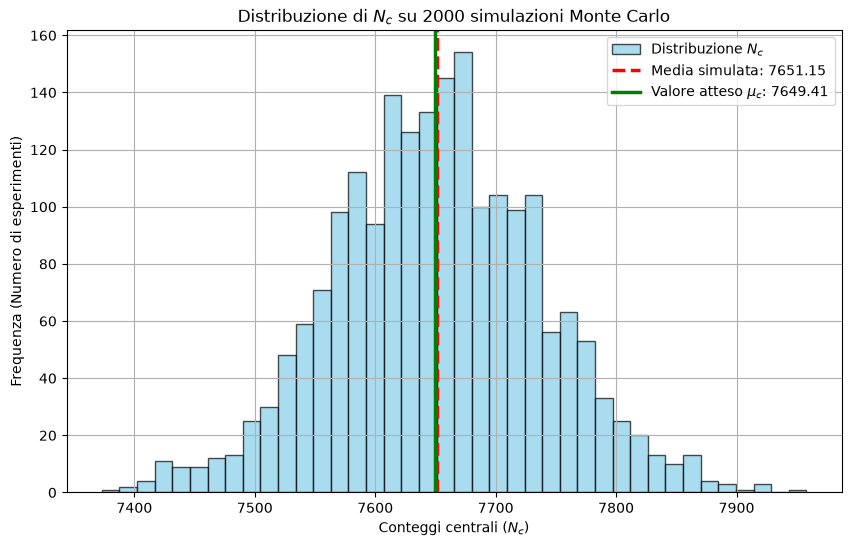

In [38]:
#Attività 3 

M=2000

n = len(y)

matrice_simulata = rng.poisson(y , size=(M , n))

mask = np.abs(x_vals) < 1.2
# Estrae solo le colonne di interesse e somma lungo le righe (ogni riga è un esperimento)
N_c_array = np.sum(matrice_simulata[:, mask], axis=1)

# Calcola la media simulata dai 2000 pseudo-esperimenti
media_Nc = np.mean(N_c_array)

sigma_Nc= N_c_array

# Imposta la dimensione del grafico 
plt.figure(figsize=(10, 6))

# Crea l'istogramma
# Essendo Nc un conteggio intero, 'bins=40' o 'bins=auto' va bene per visualizzare la distribuzione
plt.hist(N_c_array, bins=40, color='skyblue', edgecolor='black', alpha=0.7, label='Distribuzione $N_c$')

# Aggiunge la linea verticale per la media simulata
plt.axvline(media_Nc, color='red', linestyle='--', linewidth=2.5, label=f'Media simulata: {media_Nc:.2f}')

# Aggiunge la linea verticale per il valore atteso 
# (usa la variabile sum_y_c che avevi già calcolato per l'Attività 2)
plt.axvline(sum_yc, color='green', linestyle='-', linewidth=2.5, label=f'Valore atteso $\mu_c$: {sum_yc:.2f}')

# Aggiunge etichette agli assi e legenda
plt.xlabel('Conteggi centrali ($N_c$)')
plt.ylabel('Frequenza (Numero di esperimenti)')
plt.title('Distribuzione di $N_c$ su 2000 simulazioni Monte Carlo')
plt.legend()
plt.grid(True)
# Mostra il grafico
plt.show()

#y_list=[]
#for i in range(len(x_vals)):
 #   y_in=np.mean(matrice_simulata[:,i])
  #  y_list.append(y_in)

#y_mean=np.array(y_list)
y_mean= np.mean(matrice_simulata, axis=0)
sigma_y_mean = np.sqrt(y_mean)

file_dati=Path(f"dati_{M}.csv")
np.savetxt(file_dati, np.column_stack([x_vals , y_mean, sigma_y_mean]) ,delimiter=",", header="x , y , sigma_y")


  

    

